In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay

from mindscope.preprocessing import build_pipeline, TARGET

sns.set_style("whitegrid")

## 1. Loading the data

In [2]:
X_train = pd.read_csv("../data/processed/X_train.csv")
y_train = pd.read_csv("../data/processed/y_train.csv")[TARGET]

print("X_train:", X_train.shape)
print(y_train.value_counts())

X_train: (1600, 15)
Mental_Health_Risk
High      544
Medium    528
Low       528
Name: count, dtype: int64


In [3]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

print("Training part:", X_tr.shape)
print("Validation part:", X_val.shape)

Training part: (1280, 15)
Validation part: (320, 15)


## 2. Training the models

### 2.1 Defining the models

In [4]:
models = {
    "Logistic Regression": build_pipeline(LogisticRegression(max_iter=1000), X_tr),
    "KNN": build_pipeline(KNeighborsClassifier(), X_tr),
    "Random Forest": build_pipeline(RandomForestClassifier(random_state=42), X_tr),
}

print(list(models.keys()))

['Logistic Regression', 'KNN', 'Random Forest']


### 2.2 Training on the same data

In [5]:
for name, model in models.items():
    model.fit(X_tr, y_tr)
    print(name, "trained")

Logistic Regression trained
KNN trained
Random Forest trained


## 3. Evaluation of the models

### 3.1 Accuracy, precision, recall, F1-score and ROC-AUC

The target has 3 classes, so precision, recall and F1-score are averaged over the classes (macro) and the ROC-AUC is computed one-vs-rest.

In [6]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, average="macro"),
        "Recall": recall_score(y_val, y_pred, average="macro"),
        "F1-score": f1_score(y_val, y_pred, average="macro"),
        "ROC-AUC": roc_auc_score(y_val, y_proba, multi_class="ovr", labels=model.classes_),
    })

results = pd.DataFrame(results).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.744,0.752,0.743,0.745,0.913
KNN,0.612,0.602,0.611,0.604,0.784
Random Forest,0.688,0.690,0.686,0.688,0.854


### 3.2 Comparison of the metrics

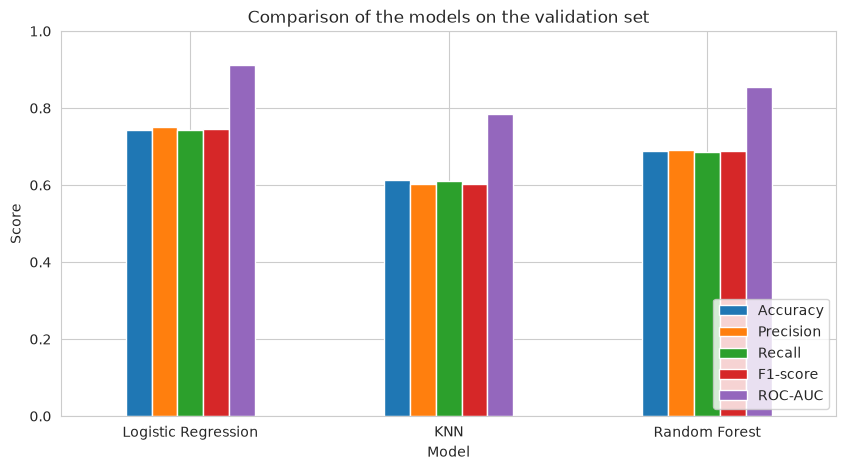

In [7]:
results.plot(kind="bar", figsize=(10, 5))
plt.title("Comparison of the models on the validation set")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

### 3.3 Confusion matrices

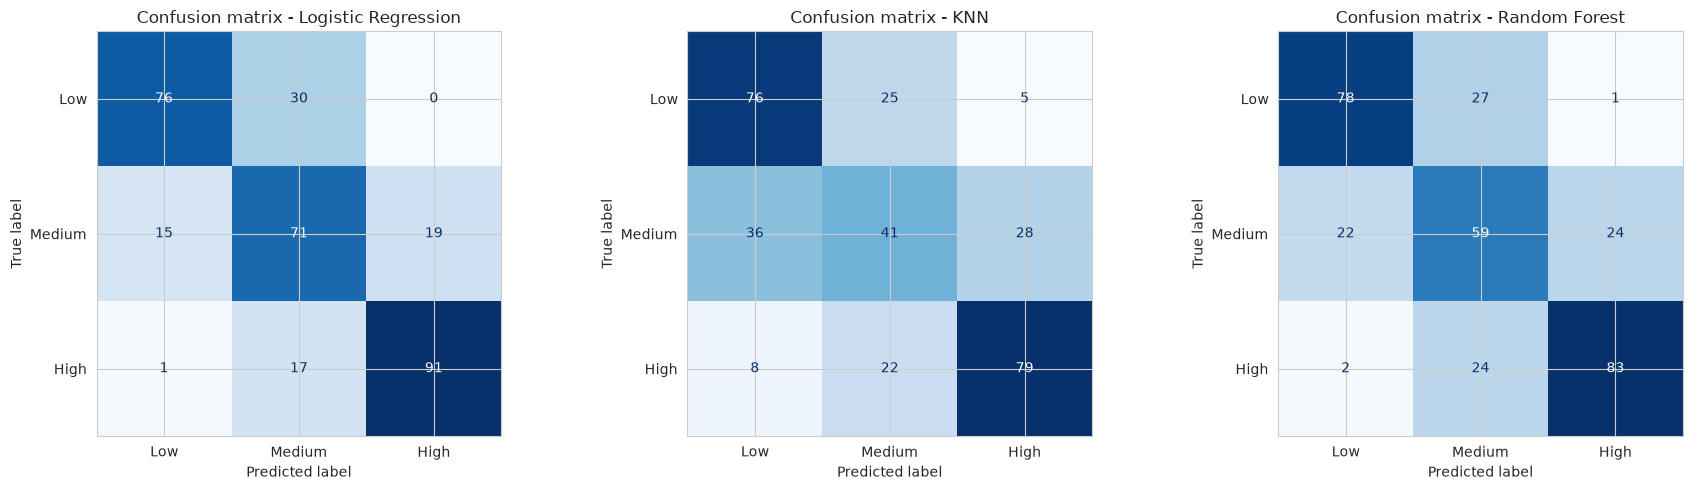

In [8]:
labels = ["Low", "Medium", "High"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_val, y_pred, labels=labels, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title("Confusion matrix - " + name)

plt.tight_layout()
plt.show()

## 4. Conclusion

In [9]:
best = results["F1-score"].idxmax()
print("Best model on F1-score:", best)
print(results.loc[best])

Best model on F1-score: Logistic Regression
Accuracy     0.744
Precision    0.752
Recall       0.743
F1-score     0.745
ROC-AUC      0.913
Name: Logistic Regression, dtype: float64
